# TP 2 : Apprentissage Profond avec TensorFlow / Keras
**Module :** Technologies IA  |  **Filière :** ILIA2 – ENSA Fès  |  **Prof :** Youness IDRISSI KHAMLICHI

Ce notebook contient :
- **Exercice 1** : reconnaissance de chiffres manuscrits (MNIST) avec un réseau Dense
- **Exercice 2** : classification de vêtements (Fashion-MNIST) avec un ANN puis un CNN

Chaque partie contient le code du TP, puis les **réponses aux questions** (cellules *Réponses*).

## 0. Préparation : chargement des données

`mnist.load_data()` télécharge les données automatiquement. Si vous n'avez pas internet, la fonction ci-dessous
lit à la place les fichiers du dataset Kaggle (dossiers `mnist/` et `fashion_mnist/` à côté du notebook).

In [1]:
import os
import numpy as np

# --- Lecture des fichiers locaux (format idx) si le téléchargement échoue ---
def trouver(dossier, nom):
    for racine, _, fichiers in os.walk(dossier):
        for f in fichiers:
            if f.replace('.', '-') == nom:
                return os.path.join(racine, f)

def lire_images(chemin):
    with open(chemin, 'rb') as f:
        data = np.frombuffer(f.read(), dtype=np.uint8, offset=16)
    return data.reshape(-1, 28, 28)

def lire_labels(chemin):
    with open(chemin, 'rb') as f:
        return np.frombuffer(f.read(), dtype=np.uint8, offset=8)

def charger_donnees(module, dossier):
    try:
        return module.load_data()          # méthode du TP (téléchargement)
    except Exception:
        print("Téléchargement impossible -> lecture des fichiers locaux :", dossier)
        x_tr = lire_images(trouver(dossier, 'train-images-idx3-ubyte'))
        y_tr = lire_labels(trouver(dossier, 'train-labels-idx1-ubyte'))
        x_te = lire_images(trouver(dossier, 't10k-images-idx3-ubyte'))
        y_te = lire_labels(trouver(dossier, 't10k-labels-idx1-ubyte'))
        return (x_tr, y_tr), (x_te, y_te)

---
# Exercice 1 : Reconnaissance de chiffres manuscrits (MNIST)
Objectif : construire un réseau de neurones **entièrement connecté (Dense)** capable de reconnaître les chiffres de 0 à 9.

## 1. Import des bibliothèques

In [2]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense, Flatten
from tensorflow.keras.datasets import mnist
import matplotlib.pyplot as plt
import numpy as np

tf.keras.utils.set_random_seed(42)   # pour avoir des résultats reproductibles
print("TensorFlow version:", tf.__version__)

I0000 00:00:1793044761.953408     162 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1793044763.448265     162 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow version: 2.21.0


**Questions :**
1. Quelle est la différence entre TensorFlow et Keras ?
2. À quoi sert la couche `Flatten` dans un réseau de neurones ?
3. Quelle version de TensorFlow est installée sur votre machine ?
4. À quoi servent `Sequential` et `Dense` ?


> **Réponses :**
> 1. **TensorFlow** est la bibliothèque de calcul (le « moteur ») qui fait les calculs sur CPU/GPU. **Keras** est une interface simple, intégrée dans TensorFlow (`tf.keras`), qui permet de construire un réseau de neurones en quelques lignes.
> 2. **`Flatten`** transforme chaque image 2D (28×28) en un vecteur 1D de 784 valeurs, car une couche `Dense` attend un vecteur et non une matrice.
> 3. La cellule affiche la version avec `tf.__version__` : **2.21.0** sur ma machine (la vôtre peut être différente).
> 4. **`Sequential`** crée un modèle où les couches sont empilées l'une après l'autre. **`Dense`** est une couche « entièrement connectée » : chaque neurone est relié à tous les neurones de la couche précédente.


## 2. Chargement et préparation du dataset

In [3]:
(x_train, y_train), (x_test, y_test) = charger_donnees(mnist, "mnist")

# Avant normalisation
print("Type des pixels avant normalisation :", x_train.dtype)
print("Valeur min / max des pixels :", x_train.min(), "/", x_train.max())

# Normalisation
x_train = x_train / 255.0
x_test = x_test / 255.0

print("Type des pixels après normalisation :", x_train.dtype)
print("Valeur min / max des pixels :", x_train.min(), "/", x_train.max())
print("x_train shape:", x_train.shape)
print("y_train shape:", y_train.shape)
print("x_test shape:", x_test.shape)

Téléchargement impossible -> lecture des fichiers locaux : mnist
Type des pixels avant normalisation : uint8
Valeur min / max des pixels : 0 / 255


Type des pixels après normalisation : float64


Valeur min / max des pixels : 0.0 / 1.0
x_train shape: (60000, 28, 28)
y_train shape: (60000,)
x_test shape: (10000, 28, 28)


**Questions :**
1. Pourquoi normalise-t-on les valeurs des pixels ?
2. Quelle est la taille d'une image et son type de données ?
3. Combien d'exemples contient le jeu d'entraînement ?


> **Réponses :**
> 1. Les pixels vont de 0 à 255. On les divise par 255 pour avoir des valeurs entre 0 et 1 : les calculs sont plus stables et le modèle **converge plus vite**.
> 2. Une image fait **28×28 pixels** (niveaux de gris). Avant normalisation le type est **`uint8`** (entiers de 0 à 255), après normalisation c'est **`float64`** (décimaux de 0 à 1).
> 3. Le jeu d'entraînement contient **60 000 exemples** (et 10 000 pour le test).


## 3. Visualisation d'échantillons

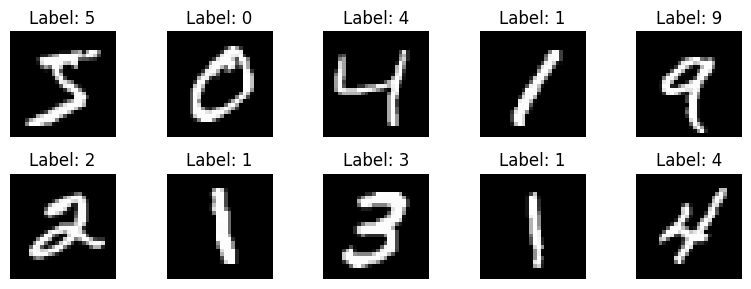

Les 10 premiers labels : [5 0 4 1 9 2 1 3 1 4]


In [4]:
plt.figure(figsize=(8,3))
for i in range(10):
    plt.subplot(2,5,i+1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')
plt.tight_layout()
plt.show()

print("Les 10 premiers labels :", y_train[:10])

**À faire :** identifier les chiffres affichés et vérifier que les labels correspondent aux images.

**Questions :**
1. Quelle commande permet de modifier le nombre d'images affichées ?
2. Que représente l'argument `cmap='gray'` ?
3. Quelle utilité a cette étape dans un projet d'IA ?


> **Réponses :**
> - Les 10 premiers labels sont `[5 0 4 1 9 2 1 3 1 4]` et correspondent bien aux chiffres affichés.
> 1. Pour changer le nombre d'images, on modifie `range(10)` et la grille `plt.subplot(2,5,i+1)`. Exemple pour 20 images : `range(20)` et `plt.subplot(4,5,i+1)`.
> 2. `cmap='gray'` affiche l'image en **niveaux de gris** (noir = 0, blanc = 255). Sans cela, matplotlib utilise des couleurs par défaut.
> 3. Cette étape sert à **vérifier que les données sont correctes** (bons labels, bonne taille, images lisibles) avant d'entraîner. Si les données sont fausses, le modèle sera faux.


## 4. Construction du modèle de réseau de neurones

In [5]:
model = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

**Questions :**
1. Combien de paramètres le modèle contient-il ?
2. Quelle est la fonction d'activation utilisée dans la couche de sortie ? Pourquoi ?
3. Quelle est la différence entre `ReLU` et `Softmax` ?


> **Réponses :**
> 1. Le modèle contient **101 770 paramètres** :
>    - couche `Dense(128)` : 784 × 128 + 128 = 100 480
>    - couche `Dense(10)` : 128 × 10 + 10 = 1 290
>    - `Flatten` n'a aucun paramètre.
> 2. La couche de sortie utilise **softmax**. Il y a 10 classes (0 à 9) et le modèle doit donner **une probabilité par chiffre** (la somme fait 1). Le chiffre prédit est celui avec la plus grande probabilité.
> 3. **ReLU** : `max(0, x)`. Elle met les valeurs négatives à 0. On l'utilise dans les **couches cachées**. **Softmax** transforme les sorties en **probabilités** ; on l'utilise dans la **couche de sortie** pour la classification multiclasse.


## 5. Compilation du modèle

In [6]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

**Questions :**
1. Qu'est-ce qu'un optimiseur ?
2. Pourquoi utilise-t-on une fonction de perte ?
3. Que se passe-t-il si on change la fonction de perte ?
4. Quelle serait la conséquence d'un mauvais choix d'optimiseur ?
5. Quelle est la différence entre `loss` et `metrics` ?


> **Réponses :**
> 1. Un **optimiseur** est l'algorithme qui **modifie les poids** du réseau pour diminuer l'erreur (ici `adam`).
> 2. La **fonction de perte** mesure l'erreur entre la prédiction et la vraie valeur. Sans elle, le modèle ne saurait pas s'il se trompe ni comment s'améliorer.
> 3. Si on change la fonction de perte, la façon de calculer l'erreur change, donc l'apprentissage change : un mauvais choix (par exemple `mse` pour de la classification) donne un apprentissage plus lent ou moins bon. De plus, `sparse_categorical_crossentropy` est faite pour des labels **entiers** (0 à 9) ; avec des labels one-hot il faut `categorical_crossentropy`, sinon on a une erreur.
> 4. Avec un mauvais optimiseur, l'apprentissage peut être **très lent**, **instable** (la perte monte et descend) ou **bloqué** sans bonne précision.
> 5. La **loss** est ce que le modèle essaie de minimiser : elle sert à entraîner. La **metric** (`accuracy`) sert seulement à **mesurer** la performance pour nous, elle n'influence pas l'entraînement.


## 6. Entraînement du modèle (5 époques)

In [7]:
history = model.fit(
    x_train, y_train,
    epochs=5,
    batch_size=32,
    validation_data=(x_test, y_test)
)

Epoch 1/5


1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9276 - loss: 0.2530 - val_accuracy: 0.9588 - val_loss: 0.1345


Epoch 2/5


1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9670 - loss: 0.1112 - val_accuracy: 0.9699 - val_loss: 0.0983


Epoch 3/5


...

Epoch 4/5


1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9836 - loss: 0.0548 - val_accuracy: 0.9750 - val_loss: 0.0828


Epoch 5/5


1875/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9880 - loss: 0.0405


1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9880 - loss: 0.0405 - val_accuracy: 0.9753 - val_loss: 0.0808


**À observer :** la précision d'entraînement augmente-t-elle ? La précision de validation suit-elle la même tendance ?

**Questions :**
1. Que représente une « époque » ?
2. Pourquoi utilise-t-on un jeu de validation ?
3. Que se passerait-il si on augmentait le nombre d'époques à 50 ?


> **Observation :** la précision d'entraînement passe de 92,8 % à 98,8 % et la précision de validation de 95,9 % à 97,5 %. Les deux augmentent, mais la validation progresse de moins en moins (97,50 % → 97,53 % aux deux dernières époques).
>
> **Réponses :**
> 1. Une **époque** est un passage complet de tout le jeu d'entraînement dans le réseau.
> 2. Le **jeu de validation** sert à vérifier le modèle sur des données qu'il n'utilise pas pour ajuster ses poids, pour voir s'il généralise bien ou s'il surapprend. (Ici, comme dans le TP, on utilise `x_test` comme validation.)
> 3. Avec 50 époques, la précision d'entraînement approcherait 100 % mais celle de validation ne bougerait presque plus, et la perte de validation pourrait remonter : c'est le **surapprentissage**. L'entraînement serait aussi plus long.


## 7. Évaluation du modèle

In [8]:
test_loss, test_acc = model.evaluate(x_test, y_test)
print(f"Test accuracy: {test_acc:.4f}")
print(f"Test loss: {test_loss:.4f}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9753 - loss: 0.0808  


Test accuracy: 0.9753
Test loss: 0.0808


**Questions :**
1. Quelle est la précision finale de votre modèle ?
2. Pourquoi la précision du test est souvent inférieure à celle d'entraînement ?
3. Que faire si le modèle surapprend (*overfitting*) ?


> **Réponses :**
> 1. La précision finale sur le test est **0,9753 (97,53 %)** avec une perte de 0,0808.
> 2. La précision du test est souvent plus faible car le modèle a **déjà vu** les données d'entraînement (il s'est adapté à elles), alors que les données de test sont **nouvelles** pour lui. Ici : 98,8 % en entraînement contre 97,5 % en test.
> 3. En cas de surapprentissage : ajouter du **Dropout**, utiliser **plus de données** (ou de la data augmentation), **réduire** la taille du modèle, **arrêter plus tôt** l'entraînement (early stopping).


## 8. Visualisation des performances

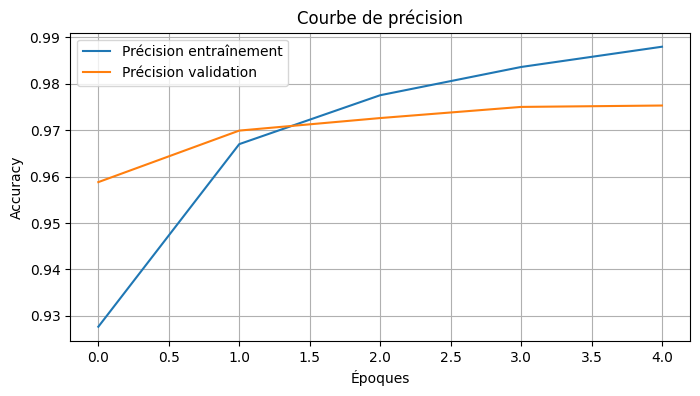

In [9]:
plt.figure(figsize=(8,4))
plt.plot(history.history['accuracy'], label='Précision entraînement')
plt.plot(history.history['val_accuracy'], label='Précision validation')
plt.title('Courbe de précision')
plt.xlabel('Époques')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

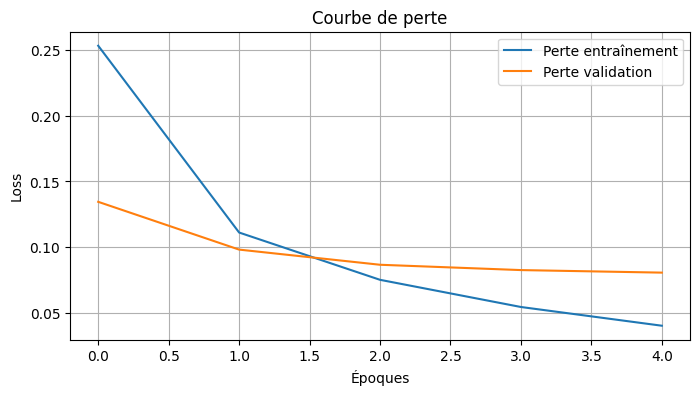

In [10]:
# Courbe de perte (demandée dans le rapport final)
plt.figure(figsize=(8,4))
plt.plot(history.history['loss'], label='Perte entraînement')
plt.plot(history.history['val_loss'], label='Perte validation')
plt.title('Courbe de perte')
plt.xlabel('Époques')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

**Questions :**
1. Que remarquez-vous sur les deux courbes ?
2. Comment détecter visuellement un surapprentissage ?
3. Quelle stratégie pourrait-on utiliser pour y remédier ?
4. Que faire si les deux courbes divergent ?


> **Réponses :**
> 1. La précision d'entraînement et de validation **augmentent** ; les pertes **diminuent**. La courbe d'entraînement est un peu au-dessus de celle de validation (98,8 % contre 97,5 %) : le modèle apprend bien, avec un petit écart.
> 2. On détecte le surapprentissage quand la précision **d'entraînement continue à monter** alors que celle de **validation stagne ou baisse** (ou quand la perte de validation remonte), donc quand l'écart entre les deux courbes grandit.
> 3. Pour y remédier : Dropout, plus de données, modèle plus simple, early stopping.
> 4. Si les deux courbes divergent, on arrête l'entraînement plus tôt et on applique les solutions ci-dessus (Dropout, régularisation, data augmentation).


## 9. Prédictions et visualisation

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 777us/step


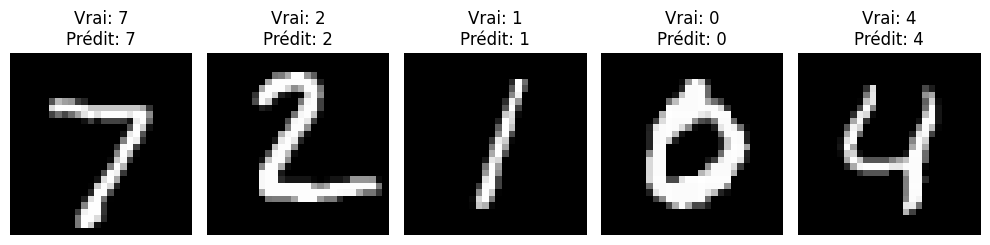

In [11]:
predictions = model.predict(x_test)

plt.figure(figsize=(10,4))
for i in range(5):
    plt.subplot(1,5,i+1)
    plt.imshow(x_test[i], cmap='gray')
    plt.title(f"Vrai: {y_test[i]}\nPrédit: {np.argmax(predictions[i])}")
    plt.axis('off')
plt.tight_layout()
plt.show()

Nombre d'erreurs : 247 sur 10000 images


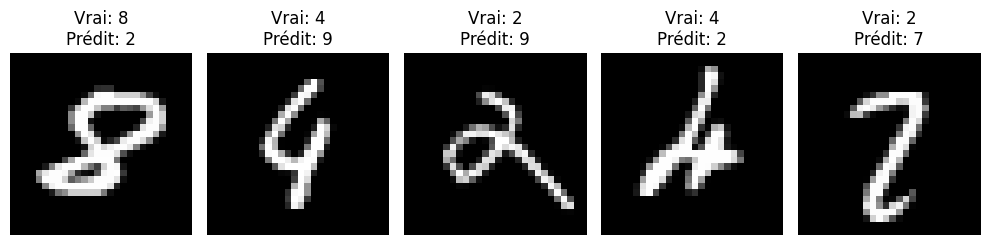

In [12]:
# Cherchons les images mal classées sur tout le jeu de test
y_pred = np.argmax(predictions, axis=1)
erreurs = np.where(y_pred != y_test)[0]
print("Nombre d'erreurs :", len(erreurs), "sur", len(y_test), "images")

plt.figure(figsize=(10,4))
for k, i in enumerate(erreurs[:5]):
    plt.subplot(1,5,k+1)
    plt.imshow(x_test[i], cmap='gray')
    plt.title(f"Vrai: {y_test[i]}\nPrédit: {y_pred[i]}")
    plt.axis('off')
plt.tight_layout()
plt.show()

**Questions :**
1. Le modèle fait-il des erreurs ? Sur quelles images ?
2. Comment expliquer une prédiction erronée ?
3. Quelle technique permettrait d'améliorer la précision (ex : CNN) ?


> **Réponses :**
> 1. Oui. Les 5 premières images du test sont bien prédites (7, 2, 1, 0, 4), mais sur les 10 000 images le modèle fait **247 erreurs** (2,47 %). Les erreurs trouvées concernent des chiffres mal écrits ou ambigus (ex. un 8 prédit comme 2, un 4 prédit comme 9, un 2 prédit comme 9).
> 2. Une erreur s'explique par une **écriture difficile** ou ambiguë (chiffre qui ressemble à un autre), ou parce que le réseau Dense ne regarde pas la forme de l'image (après `Flatten`, il perd la position des pixels voisins).
> 3. Un **CNN** améliorerait la précision car il analyse les formes locales de l'image. On peut aussi ajouter des couches, du Dropout ou faire de la data augmentation.


## Travail demandé : résumé de l'exercice 1

In [13]:
print("Précision finale (test) :", round(test_acc, 4))
print("Perte finale (test)     :", round(test_loss, 4))
print("Précision finale entraînement :", round(history.history['accuracy'][-1], 4))

Précision finale (test) : 0.9753
Perte finale (test)     : 0.0808
Précision finale entraînement : 0.988


**Analyse personnelle (exercice 1)** : voir la cellule ci-dessous.


> **Analyse personnelle (exercice 1) :**
>
> Mon réseau Dense (101 770 paramètres) atteint **97,53 % de précision sur le test** en seulement 5 époques. La précision d'entraînement est de 98,8 % : l'écart est petit, donc le modèle généralise bien, mais on voit que la validation progresse de moins en moins. Il fait encore 247 erreurs sur 10 000 images, surtout sur des chiffres mal écrits.
>
> *Difficultés :* comprendre les dimensions des données (28×28 puis 784 après `Flatten`), la différence entre `sparse_categorical_crossentropy` et `categorical_crossentropy`, et le chargement du dataset quand le téléchargement ne marche pas (j'ai utilisé les fichiers du dataset Kaggle).
>
> *Améliorations possibles :* ajouter une couche cachée ou plus de neurones, ajouter du Dropout, essayer d'autres hyperparamètres (batch size, nombre d'époques avec early stopping), et surtout utiliser un **CNN**, mieux adapté aux images.


---
# Exercice 2 : Classification d'images avec Fashion-MNIST
Objectif : construire un **ANN** puis un **CNN**, analyser les résultats et comprendre le rôle des **fonctions d'activation**.

Dataset : 70 000 images (60 000 train, 10 000 test), 28×28 pixels en niveaux de gris, 10 classes de vêtements.

In [14]:
import tensorflow as tf
from tensorflow.keras.datasets import fashion_mnist
import matplotlib.pyplot as plt
import seaborn as sns

# Pour la reproductibilité
tf.random.set_seed(42)

# Chargement du dataset
(X_train, y_train), (X_test, y_test) = charger_donnees(fashion_mnist, "fashion_mnist")

# Noms des classes (en français)
noms_classes = ['T-shirt', 'Pantalon', 'Pull', 'Robe', 'Manteau',
                'Sandale', 'Chemise', 'Basket', 'Sac', 'Bottine']

Téléchargement impossible -> lecture des fichiers locaux : fashion_mnist


## Étape 1 – Exploration du jeu de données

### A. Dimensions et types

In [15]:
print("Dimensions du train set :", X_train.shape)
print("Dimensions du test set :", X_test.shape)
print("Type des données :", X_train.dtype)
print("Valeurs des pixels : de", X_train.min(), "à", X_train.max())

Dimensions du train set : (60000, 28, 28)
Dimensions du test set : (10000, 28, 28)
Type des données : uint8
Valeurs des pixels : de 0 à 255


### B. Visualisation d'exemples

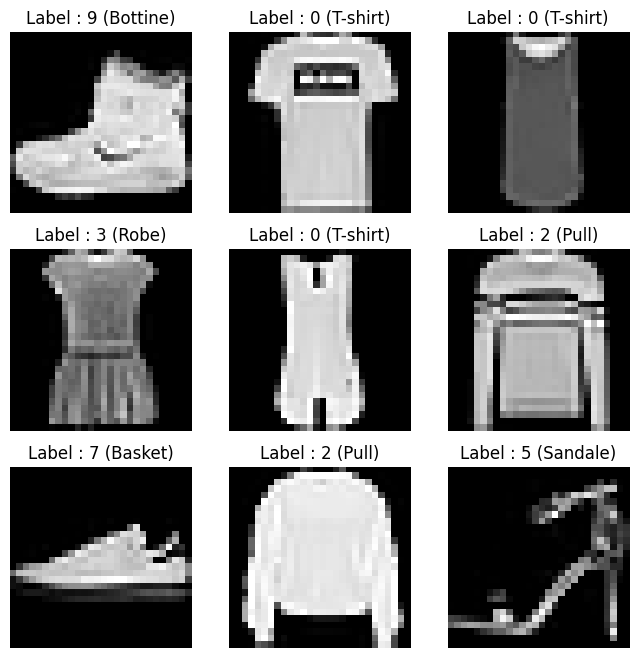

In [16]:
plt.figure(figsize=(8, 8))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title(f"Label : {y_train[i]} ({noms_classes[y_train[i]]})")
    plt.axis('off')
plt.show()

**Question :** Que remarquez-vous sur la nature des données et la taille des images ?


> **Réponse :** les données sont des **images en niveaux de gris**, toutes de la même petite taille **28×28 pixels** (1 seul canal), avec des pixels de type `uint8` (0 à 255). Il y a 60 000 images d'entraînement et 10 000 de test. Ce sont des vêtements et chaussures, et certaines classes se ressemblent beaucoup (T-shirt, chemise, pull), donc c'est plus difficile que MNIST.


## Étape 2 – Prétraitement des données

In [17]:
from tensorflow.keras.utils import to_categorical

# Normalisation des pixels entre 0 et 1
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

# Encodage one-hot des labels
y_train_cat = to_categorical(y_train, 10)
y_test_cat = to_categorical(y_test, 10)

print("Valeurs des pixels : de", X_train.min(), "à", X_train.max())
print("Label 0 avant :", y_train[0], "-> après one-hot :", y_train_cat[0])

Valeurs des pixels : de 0.0 à 1.0
Label 0 avant : 9 -> après one-hot : [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]


**Questions :**
1. Pourquoi faut-il normaliser les images ?
2. Quelle est l'importance du one-hot encoding dans un problème de classification multiclasse ?


> **Réponses :**
> 1. On normalise (pixels entre 0 et 1) pour que les valeurs soient petites et de même échelle : l'entraînement est **plus rapide et plus stable**.
> 2. Les classes sont des **catégories** sans ordre (le « 9 » n'est pas « plus grand » que le « 0 »). Le **one-hot** représente chaque classe par un vecteur de 10 valeurs avec un seul 1 (ex. classe 9 → `[0,0,0,0,0,0,0,0,0,1]`). Cela correspond aux 10 sorties du softmax et à la fonction `categorical_crossentropy`.


## Étape 3 – Création d'un modèle dense (ANN)

### Création du modèle de base

In [18]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Flatten, Dense, Dropout

model = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.2),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

### Compilation et entraînement

In [19]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    X_train, y_train_cat,
    epochs=10,
    batch_size=128,
    validation_split=0.2
)

Epoch 1/10


375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7789 - loss: 0.6314 - val_accuracy: 0.8418 - val_loss: 0.4410


Epoch 2/10


375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8464 - loss: 0.4313 - val_accuracy: 0.8577 - val_loss: 0.3961


Epoch 3/10


...

375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8863 - loss: 0.3096 - val_accuracy: 0.8767 - val_loss: 0.3342


Epoch 9/10


375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8891 - loss: 0.3003 - val_accuracy: 0.8755 - val_loss: 0.3335


Epoch 10/10


375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8913 - loss: 0.2930 - val_accuracy: 0.8762 - val_loss: 0.3426


### Visualisation

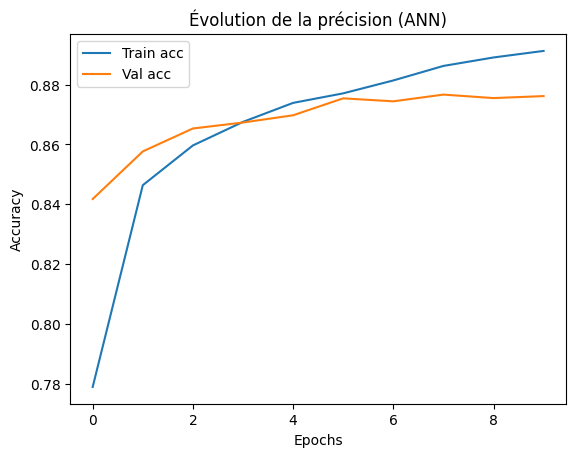

In [20]:
plt.plot(history.history['accuracy'], label='Train acc')
plt.plot(history.history['val_accuracy'], label='Val acc')
plt.legend()
plt.title('Évolution de la précision (ANN)')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.show()

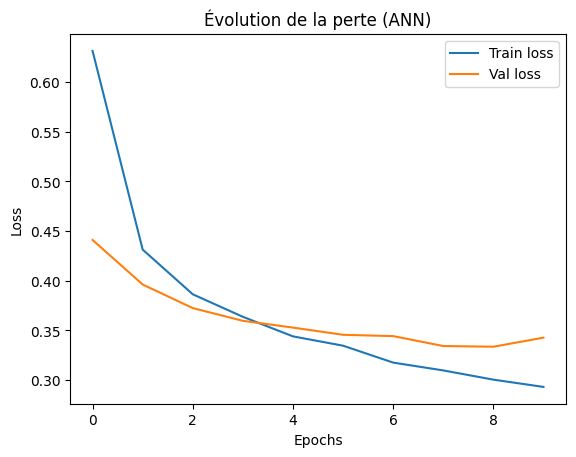

In [21]:
# Courbe de perte
plt.plot(history.history['loss'], label='Train loss')
plt.plot(history.history['val_loss'], label='Val loss')
plt.legend()
plt.title('Évolution de la perte (ANN)')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.show()

**Questions :**
1. Pourquoi utilise-t-on la fonction d'activation **ReLU** ici ?
2. Quelle est la différence entre `accuracy` et `val_accuracy` ?
3. Que se passe-t-il si l'on augmente le nombre d'époques à 50 ?


> **Réponses :**
> 1. **ReLU** est simple, rapide à calculer et évite le problème de la disparition du gradient : le réseau apprend vite et bien.
> 2. **`accuracy`** est la précision sur les données d'**entraînement** ; **`val_accuracy`** est la précision sur les données de **validation** (20 % des données, non utilisées pour ajuster les poids). La seconde montre la vraie capacité de généralisation.
> 3. Avec 50 époques, la précision d'entraînement continuerait à monter, mais la validation stagnerait vers 88-89 % et la perte de validation remonterait : **surapprentissage**. On voit déjà un début de remontée de la `val_loss` à la 10<sup>e</sup> époque (0,334 → 0,343).
>
> **Résultat de l'ANN :** précision sur le test = **0,8654 (86,5 %)**, avec 109 386 paramètres.


### Évaluation finale

In [22]:
test_loss, test_acc = model.evaluate(X_test, y_test_cat)
print("Précision sur le test set :", test_acc)
acc_ann = test_acc

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8654 - loss: 0.3678


Précision sur le test set : 0.8654000163078308


## Étape 4 — Introduction aux fonctions d'activation
Objectif : comparer **sigmoïde**, **tanh**, **ReLU** et **LeakyReLU** (5 époques chacune).

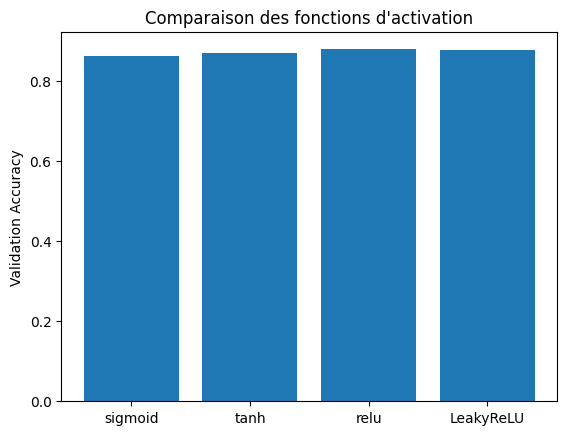

sigmoid    -> val_accuracy = 0.8634
tanh       -> val_accuracy = 0.8706
relu       -> val_accuracy = 0.8795
LeakyReLU  -> val_accuracy = 0.8783


In [23]:
from tensorflow.keras.layers import LeakyReLU

activations = ['sigmoid', 'tanh', 'relu']
results = {}

for act in activations:
    model_act = Sequential([
        Input(shape=(28,28)),
        Flatten(),
        Dense(128, activation=act),
        Dense(64, activation=act),
        Dense(10, activation='softmax')
    ])

    model_act.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    h = model_act.fit(X_train, y_train_cat, epochs=5, batch_size=128, validation_split=0.2, verbose=0)
    results[act] = h.history['val_accuracy'][-1]

# Leaky ReLU
model_leaky = Sequential([
    Input(shape=(28,28)),
    Flatten(),
    Dense(128),
    LeakyReLU(0.1),
    Dense(64),
    LeakyReLU(0.1),
    Dense(10, activation='softmax')
])
model_leaky.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
h = model_leaky.fit(X_train, y_train_cat, epochs=5, batch_size=128, validation_split=0.2, verbose=0)
results['LeakyReLU'] = h.history['val_accuracy'][-1]

plt.bar(results.keys(), results.values())
plt.title("Comparaison des fonctions d'activation")
plt.ylabel("Validation Accuracy")
plt.show()

for nom, valeur in results.items():
    print(f"{nom:10s} -> val_accuracy = {valeur:.4f}")

**Questions :**
1. Quelle fonction d'activation donne les meilleurs résultats ?
2. Pourquoi les fonctions **sigmoïde** et **tanh** sont moins utilisées dans les couches cachées ?
3. À quoi sert **LeakyReLU** ?


> **Résultats (validation après 5 époques) :** ReLU 0,8795 ; LeakyReLU 0,8783 ; tanh 0,8706 ; sigmoïde 0,8634.
>
> **Réponses :**
> 1. **ReLU** donne le meilleur résultat, suivie de très près par **LeakyReLU**. Les écarts sont petits et peuvent varier un peu d'une exécution à l'autre.
> 2. **Sigmoïde** et **tanh** « saturent » : pour de grandes valeurs, leur courbe est presque plate, donc le gradient devient très petit (**vanishing gradient**) et l'apprentissage est lent dans les réseaux profonds. Elles sont aussi plus lourdes à calculer.
> 3. **LeakyReLU** laisse passer une petite pente pour les valeurs négatives (ici 0,1 × x) au lieu de mettre 0. Cela évite les neurones « morts » (qui restent toujours à 0 avec ReLU).


## Étape 5 : Modèle CNN (Convolutional Neural Network)

### Création du modèle CNN

In [24]:
from tensorflow.keras.layers import Conv2D, MaxPooling2D

# Reshape pour ajouter la dimension "canal"
X_train_cnn = X_train.reshape(-1, 28, 28, 1)
X_test_cnn = X_test.reshape(-1, 28, 28, 1)

cnn = Sequential([
    Input(shape=(28, 28, 1)),
    Conv2D(32, (3,3), activation='relu'),
    MaxPooling2D((2,2)),
    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D((2,2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(10, activation='softmax')
])
cnn.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
cnn.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_6 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

### Entraînement

In [25]:
history_cnn = cnn.fit(
    X_train_cnn, y_train_cat,
    epochs=10,
    batch_size=128,
    validation_split=0.2
)

Epoch 1/10


375/375 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - accuracy: 0.7680 - loss: 0.6418 - val_accuracy: 0.8527 - val_loss: 0.4134


Epoch 2/10


375/375 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.8530 - loss: 0.4046


375/375 ━━━━━━━━━━━━━━━━━━━━ 10s 27ms/step - accuracy: 0.8530 - loss: 0.4046 - val_accuracy: 0.8740 - val_loss: 0.3510


...

Epoch 9/10


375/375 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.9162 - loss: 0.2281


375/375 ━━━━━━━━━━━━━━━━━━━━ 10s 27ms/step - accuracy: 0.9162 - loss: 0.2281 - val_accuracy: 0.9082 - val_loss: 0.2510


Epoch 10/10


375/375 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - accuracy: 0.9208 - loss: 0.2145 - val_accuracy: 0.9091 - val_loss: 0.2458


### Évaluation

In [26]:
test_loss, test_acc = cnn.evaluate(X_test_cnn, y_test_cat)
print("Précision CNN sur test set :", test_acc)
acc_cnn = test_acc

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9040 - loss: 0.2619


Précision CNN sur test set : 0.9039999842643738


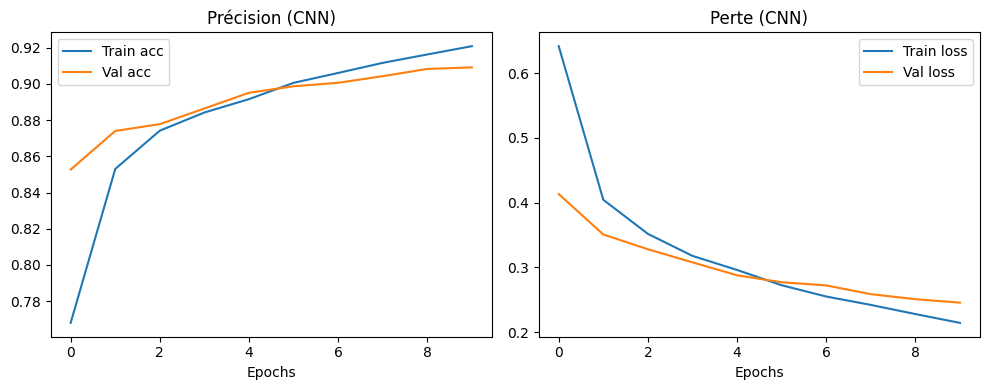

In [27]:
# Courbes du CNN
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(history_cnn.history['accuracy'], label='Train acc')
plt.plot(history_cnn.history['val_accuracy'], label='Val acc')
plt.title('Précision (CNN)')
plt.xlabel('Epochs')
plt.legend()
plt.subplot(1,2,2)
plt.plot(history_cnn.history['loss'], label='Train loss')
plt.plot(history_cnn.history['val_loss'], label='Val loss')
plt.title('Perte (CNN)')
plt.xlabel('Epochs')
plt.legend()
plt.tight_layout()
plt.show()

**Questions :**
1. Quelle est la différence entre un **ANN** et un **CNN** ?
2. Pourquoi le CNN donne-t-il généralement de meilleurs résultats ?
3. Quel est le rôle des couches de **Pooling** ?


> **Résultat :** CNN = **0,9040 (90,4 %)** sur le test contre 86,5 % pour l'ANN (225 034 paramètres).
>
> **Réponses :**
> 1. Un **ANN** (Dense) relie chaque pixel à chaque neurone après `Flatten`, sans tenir compte de la position des pixels. Un **CNN** utilise des **filtres de convolution** qui parcourent l'image pour détecter des motifs (bords, formes).
> 2. Le CNN garde la **structure 2D** de l'image et repère des motifs locaux (bords, textures) quel que soit leur endroit dans l'image. Les filtres sont réutilisés sur toute l'image, donc les couches de convolution ont peu de paramètres.
> 3. Le **Pooling** (`MaxPooling2D`) **réduit la taille** des images (28 → 13 puis 11 → 5) en gardant les valeurs importantes. Cela diminue les calculs, limite le surapprentissage et rend le modèle moins sensible aux petits décalages.


## Étape 6 — Visualisation des performances

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


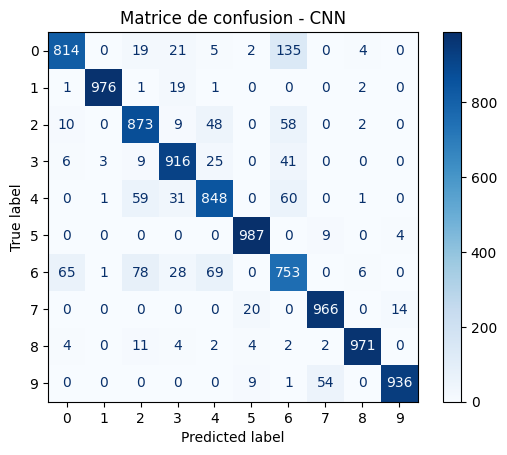

In [28]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import numpy as np

y_pred = np.argmax(cnn.predict(X_test_cnn), axis=1)
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")
plt.title("Matrice de confusion - CNN")
plt.show()

In [29]:
# Les confusions les plus fréquentes (en dehors de la diagonale)
cm = confusion_matrix(y_test, y_pred)
paires = []
for i in range(10):
    for j in range(10):
        if i != j:
            paires.append((cm[i, j], noms_classes[i], noms_classes[j]))
paires.sort(reverse=True)

print("Les 5 confusions les plus fréquentes :")
for nb, vrai, predit in paires[:5]:
    print(f" - {vrai} pris pour {predit} : {nb} fois")

Les 5 confusions les plus fréquentes :
 - T-shirt pris pour Chemise : 135 fois
 - Chemise pris pour Pull : 78 fois
 - Chemise pris pour Manteau : 69 fois
 - Chemise pris pour T-shirt : 65 fois
 - Manteau pris pour Chemise : 60 fois


**Questions :**
1. Quelles classes sont le plus souvent confondues ?
2. Comment peut-on réduire ces erreurs de classification ?


> **Réponses :**
> 1. Les confusions les plus fréquentes sont : **T-shirt pris pour Chemise (135 fois)**, Chemise prise pour Pull (78), Chemise prise pour Manteau (69), Chemise prise pour T-shirt (65) et Manteau pris pour Chemise (60). La classe **Chemise** est la plus souvent confondue : elle ressemble à T-shirt, Pull et Manteau.
> 2. Pour réduire ces erreurs : entraîner plus longtemps, ajouter des couches de convolution ou de filtres, utiliser la data augmentation, avoir plus de données, ou ajouter du Dropout/BatchNormalization.


## Étape 7 : Data Augmentation

Pour comparer correctement, on crée un **nouveau CNN** (mêmes couches, poids repartis de zéro) avec `clone_model`.

In [30]:
try:
    from tensorflow.keras.preprocessing.image import ImageDataGenerator
except ImportError:
    from keras.preprocessing.image import ImageDataGenerator

datagen = ImageDataGenerator(
    rotation_range=10,
    zoom_range=0.1,
    horizontal_flip=True
)

datagen.fit(X_train_cnn)

# Nouveau CNN avec la même architecture
cnn_aug = tf.keras.models.clone_model(cnn)
cnn_aug.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

history_aug = cnn_aug.fit(
    datagen.flow(X_train_cnn, y_train_cat, batch_size=128),
    epochs=10,
    validation_data=(X_test_cnn, y_test_cat)
)

Epoch 1/10


469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.7337 - loss: 0.7151


469/469 ━━━━━━━━━━━━━━━━━━━━ 20s 41ms/step - accuracy: 0.7337 - loss: 0.7151 - val_accuracy: 0.8250 - val_loss: 0.4647


Epoch 2/10


469/469 ━━━━━━━━━━━━━━━━━━━━ 22s 43ms/step - accuracy: 0.8168 - loss: 0.4906 - val_accuracy: 0.8492 - val_loss: 0.4061


...

469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.8810 - loss: 0.3228


469/469 ━━━━━━━━━━━━━━━━━━━━ 21s 43ms/step - accuracy: 0.8810 - loss: 0.3228 - val_accuracy: 0.8815 - val_loss: 0.3258


Epoch 10/10


469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.8834 - loss: 0.3142


469/469 ━━━━━━━━━━━━━━━━━━━━ 19s 41ms/step - accuracy: 0.8834 - loss: 0.3142 - val_accuracy: 0.8966 - val_loss: 0.2848


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8966 - loss: 0.2848


Précision CNN + Data Augmentation sur test set : 0.8966000080108643
=== Résumé des précisions sur le test set ===
ANN                    : 0.8654
CNN                    : 0.9040
CNN + Data Augmentation: 0.8966


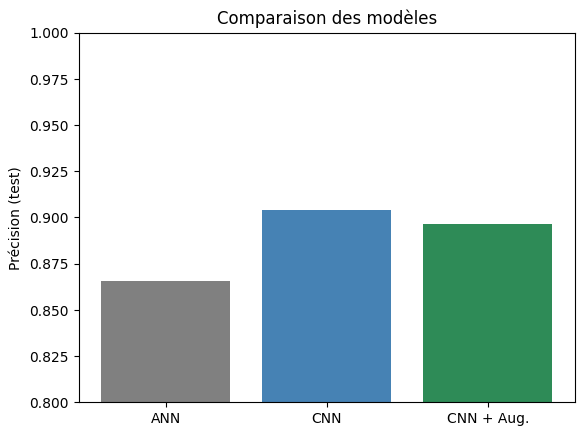

In [31]:
test_loss, acc_aug = cnn_aug.evaluate(X_test_cnn, y_test_cat)
print("Précision CNN + Data Augmentation sur test set :", acc_aug)

# Comparaison finale
print()
print("=== Résumé des précisions sur le test set ===")
print(f"ANN                    : {acc_ann:.4f}")
print(f"CNN                    : {acc_cnn:.4f}")
print(f"CNN + Data Augmentation: {acc_aug:.4f}")

plt.bar(['ANN', 'CNN', 'CNN + Aug.'], [acc_ann, acc_cnn, acc_aug], color=['gray','steelblue','seagreen'])
plt.ylim(0.8, 1.0)
plt.ylabel('Précision (test)')
plt.title('Comparaison des modèles')
plt.show()

**Questions :**
1. Quel est l'intérêt de la **Data Augmentation** ?
2. Quels types de transformations semblent les plus efficaces pour ce dataset ?


> **Résultat :** CNN + data augmentation = **0,8966 (89,7 %)** sur le test, contre 90,4 % pour le CNN sans augmentation.
>
> **Réponses :**
> 1. La **data augmentation** crée de nouvelles images à partir des images existantes (rotation, zoom, symétrie). Le modèle voit plus de variété, **généralise mieux** et surapprend moins.
> 2. Les transformations les plus adaptées ici : **petite rotation**, **léger zoom** et **symétrie horizontale** (un vêtement retourné gauche-droite reste réaliste). Une symétrie **verticale** ne serait pas adaptée (un pantalon à l'envers n'existe pas).
>
> **Remarque :** dans mon essai, l'augmentation n'améliore pas le résultat après 10 époques. Le modèle voit des images plus difficiles, il apprend plus lentement (précision d'entraînement 88,3 % < validation 89,7 %), donc il n'y a pas de surapprentissage à corriger ici. Avec plus d'époques, l'augmentation pourrait devenir utile.


## Conclusion générale


**Résumé des résultats sur le jeu de test :**

| Modèle | Précision test |
|---|---|
| Exercice 1 : MNIST, réseau Dense | 97,53 % |
| Exercice 2 : ANN (Fashion-MNIST) | 86,54 % |
| Exercice 2 : CNN | 90,40 % |
| Exercice 2 : CNN + Data Augmentation | 89,66 % |

**Analyse personnelle (exercice 2) :**

- Le **CNN (90,4 %)** est meilleur que l'ANN (86,5 %), car il utilise la structure 2D des images. Fashion-MNIST est plus difficile que MNIST (97,5 %) parce que des vêtements se ressemblent, surtout la chemise, le T-shirt, le pull et le manteau (voir la matrice de confusion).
- Pour les activations, **ReLU** et **LeakyReLU** sont les meilleures ; sigmoïde et tanh sont un peu moins bonnes.
- La data augmentation n'a pas amélioré le résultat en 10 époques ; il faudrait plus d'époques pour voir son effet.
- *Difficultés :* comprendre les dimensions (ajout du canal pour le CNN), le one-hot et le choix de la loss, et le temps d'entraînement du CNN.
- *Améliorations :* plus d'époques avec early stopping, plus de couches de convolution, BatchNormalization, réglage des hyperparamètres (learning rate, batch size, Dropout).

*Remarque : les valeurs peuvent varier légèrement d'une exécution à l'autre (initialisation aléatoire des poids).*
